# Compare Diffusivity and Plot Fluxes

New notebook for comparing eddy diffusivity plots from both methods, similar to the comp_fraction notebook for variance production/dissipation terms. Also will plot eddy fluxes of heat and salt.

In [1]:
import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
import matplotlib.colors as colors
from matplotlib.cm import ScalarMappable
import cartopy.crs as ccrs
import cmocean.cm as cmo
import json

## Load Datasets

In [2]:
# my estimates
ds_pbar_grid = xr.open_dataset('/swot/SUM05/amf2288/ds_pbar_grid_var.nc')
ds_pbar_grad = xr.open_dataset('/swot/SUM05/amf2288/ds_pbar_grad_clip_mask.nc')
ds_pbar_grid = ds_pbar_grid.assign_coords(LON_left = ds_pbar_grad.LON_left,LAT_left = ds_pbar_grad.LAT_left)
ds_amf = xr.merge([ds_pbar_grid, ds_pbar_grad.drop_vars({'DENSITY'})])

/home/amf2288/miniconda3/envs/Argo_Feb_25/lib/python3.11/site-packages/xarray/backends/plugins.py:80: RuntimeWarning: Engine 'erddapy' loading failed:
cannot import name 'T_PathFileOrDataStore' from 'xarray.backends.common' (/home/amf2288/miniconda3/envs/Argo_Feb_25/lib/python3.11/site-packages/xarray/backends/common.py)
  warnings.warn(f"Engine {name!r} loading failed:\n{ex}", RuntimeWarning)


In [10]:
ds_eb = xr.open_dataset("/swot/SUM05/amf2288/argo_mixing/global_datasets_20261116/global_binned_3deg.nc", engine="netcdf4")
ds_eb.attrs = json.loads(ds_eb.attrs["density_grid_attrs_json"])

## Compare Eddy Diffusivity

In [11]:
ds_eb

<xarray.Dataset>
Dimensions:                     (pressure_bin: 41, latitude: 60,
                                 longitude: 120, bounds: 2,
                                 neutral_density_bin: 577)
Coordinates:
  * pressure_bin                (pressure_bin) float64 25.0 75.0 ... 2.025e+03
  * latitude                    (latitude) float64 -88.5 -85.5 ... 85.5 88.5
  * longitude                   (longitude) float64 -178.5 -175.5 ... 178.5
  * neutral_density_bin         (neutral_density_bin) float64 0.025 ... 28.83
Dimensions without coordinates: bounds
Data variables: (12/57)
    pressure_bin_bounds         (pressure_bin, bounds) float64 ...
    latitude_bounds             (latitude, bounds) int64 ...
    longitude_bounds            (longitude, bounds) int64 ...
    Krho_pressure               (pressure_bin, latitude, longitude) float64 ...
    Krho_sum_pressure           (pressure_bin, latitude, longitude) float64 ...
    Krho_count_pressure         (pressure_bin, latitude, longitude) int64 ...
    ...                          ...
    PSdia_count_density         (neutral_density_bin, latitude, longitude) int64 ...
    PSiso_density               (neutral_density_bin, latitude, longitude) float64 ...
    PSiso_sum_density           (neutral_density_bin, latitude, longitude) float64 ...
    PSiso_count_density         (neutral_density_bin, latitude, longitude) int64 ...
    observation_count_density   (neutral_density_bin, latitude, longitude) int64 ...
    profile_count_density       (neutral_density_bin, latitude, longitude) int64 ...
Attributes: (12/19)
    horizontal_resolution_degrees:  3.0
    vertical_bin_width:             0.05
    bin_rule:                       lower-inclusive, upper-exclusive; longitu...
    vertical_range:                 all observed finite coordinate bins, incl...
    weighting:                      one vote per finite Zfs observation, not ...
    pressure_coordinate:            mean pressure where abs(Zmeas-Zfs)<25 m, ...
    ...                             ...
    sampling_note:                  200-m mixing windows overlap at 50-m spac...
    source_manifest:                /swot/SUM05/amf2288/argo_mixing/global_re...
    source_manifest_sha256:         50baf86caf1b60a7c0197b3cf562f45cf87dc1867...
    signature:                      5fb0cf52dd6b313b89a1ba7775d1b984a2452fcde...
    accepted_profiles:              1117885
    source_partitions:              25686

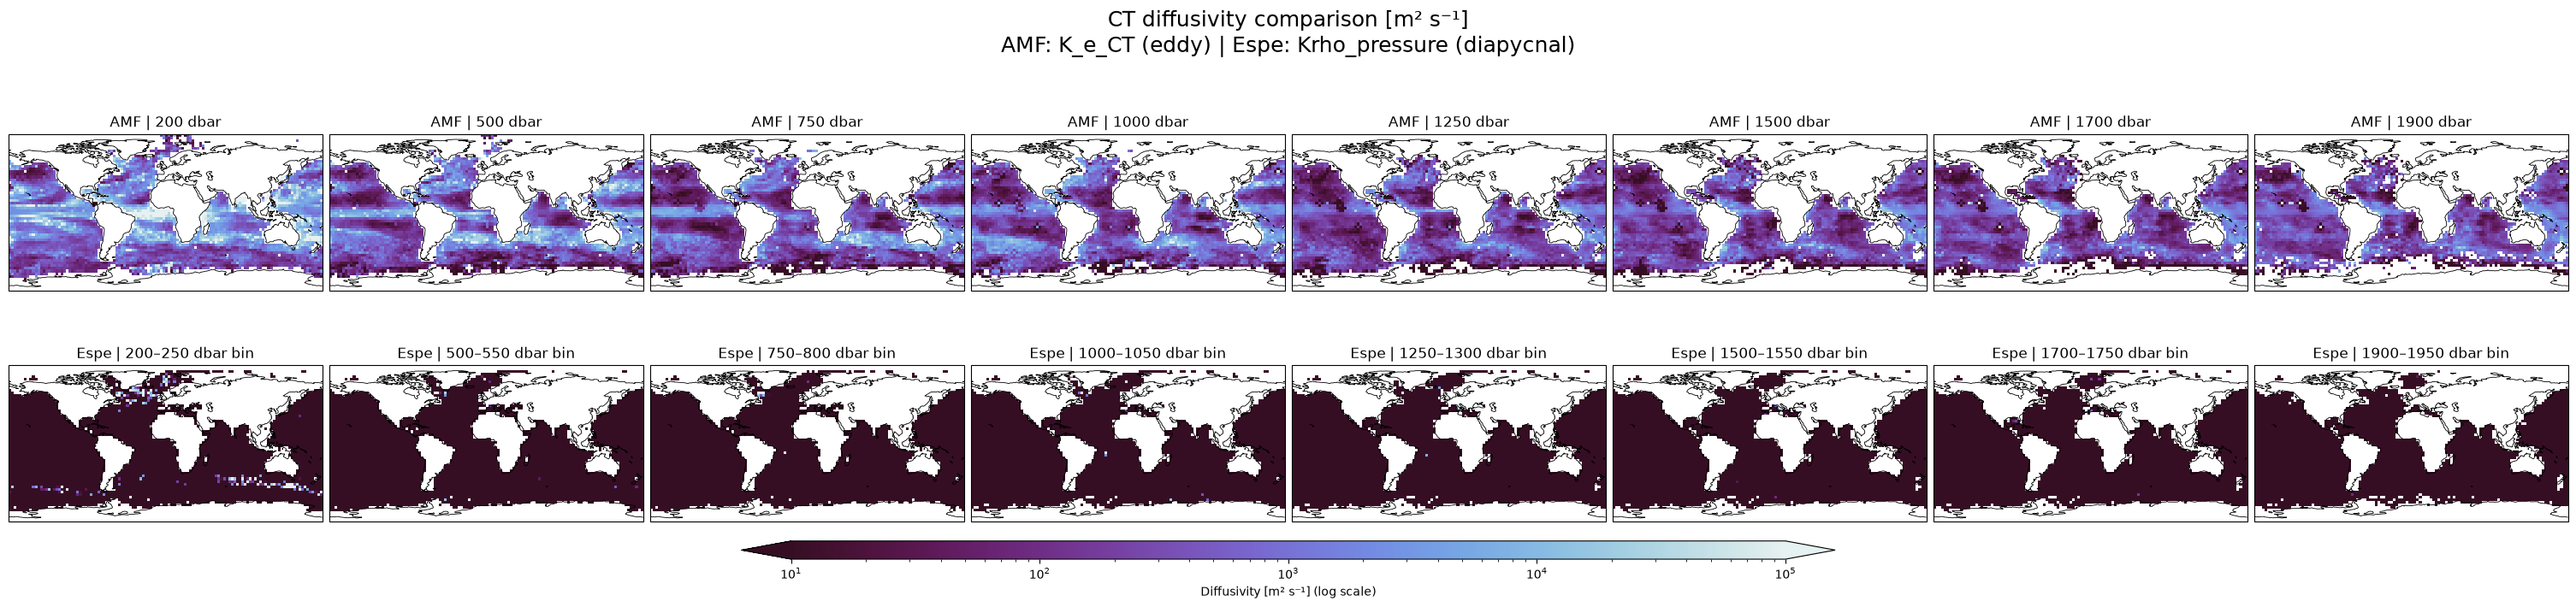

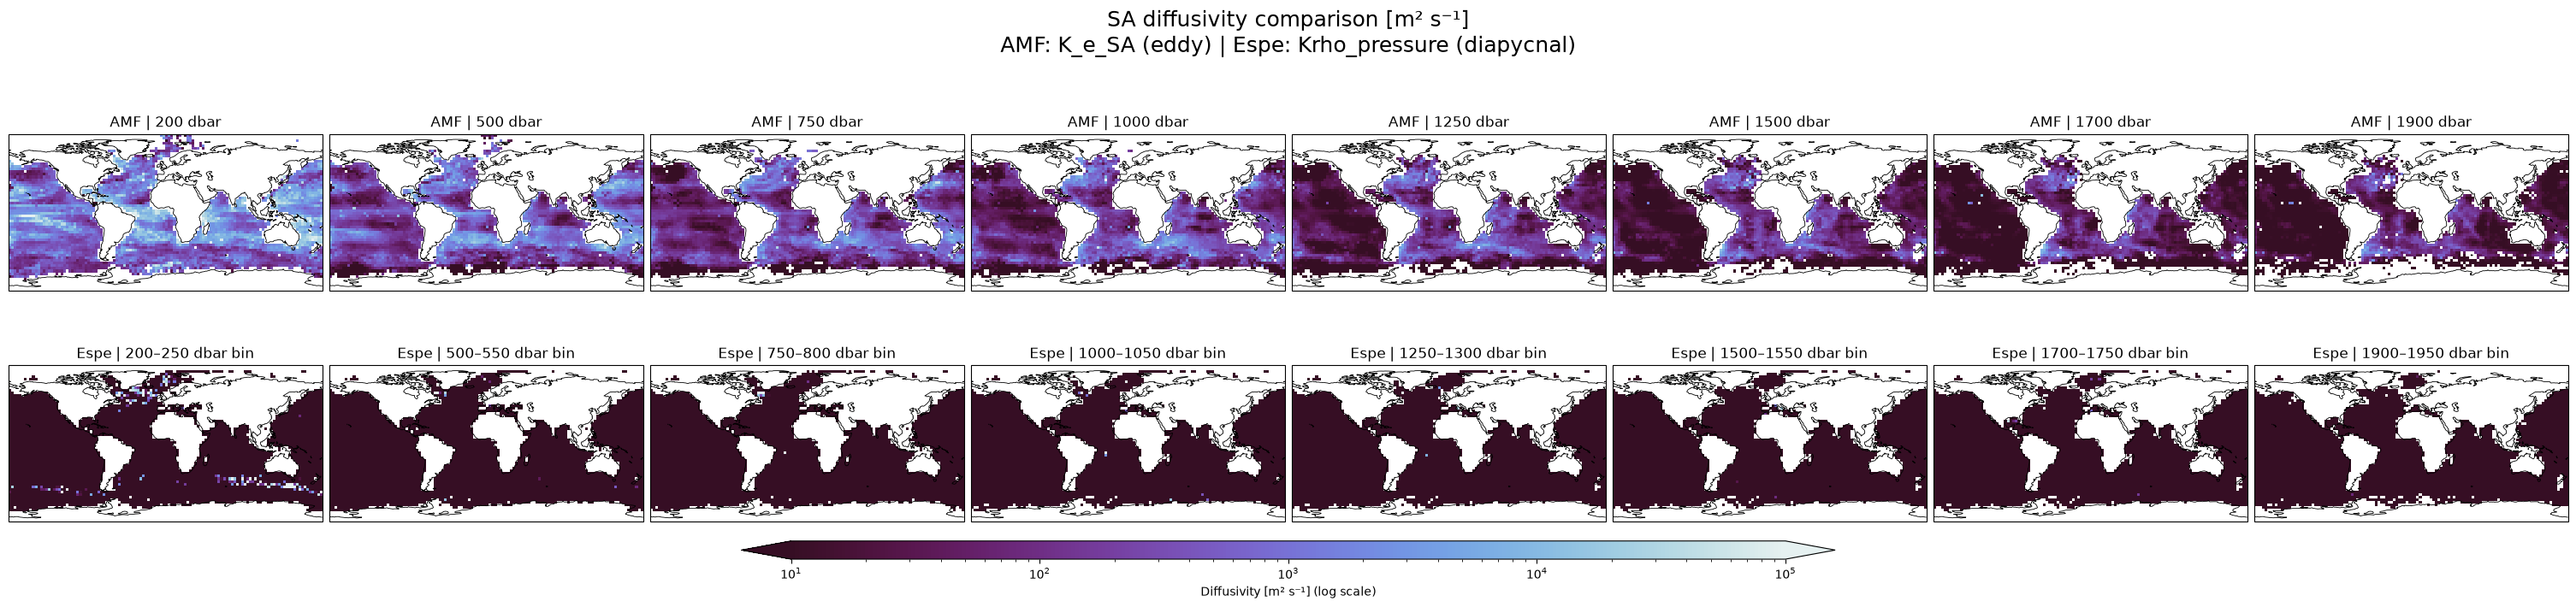

In [ ]:
# Edit (minimum, maximum) colorbar limits in m² s⁻¹; limits must be positive.
# Each tracer uses one log scale shared by AMF, Espe, and all pressure levels.
CT_DIFFUSIVITY_LIMITS = (1e1, 1e5)
SA_DIFFUSIVITY_LIMITS = (1e1, 1e5)
DIFFUSIVITY_CMAP = cmo.dense_r
depths = [200, 500, 750, 1000, 1250, 1500, 1700, 1900]

# K_e_CT/K_e_SA are eddy diffusivities; Krho_pressure is diapycnal diffusivity.
# Match comp_fraction's nearest-pressure selection and label actual levels/bins.
diffusivity_figures = {}
diffusivity_axes = {}

for tracer, amf_name, limits in [
    ("CT", "K_e_CT", CT_DIFFUSIVITY_LIMITS),
    ("SA", "K_e_SA", SA_DIFFUSIVITY_LIMITS),
]:
    diffusivity_norm = colors.LogNorm(vmin=limits[0], vmax=limits[1])
    diffusivity_ticks = np.geomspace(*limits, 5)
    fig, axes = plt.subplots(
        2, len(depths), figsize=(30, 7), squeeze=False,
        subplot_kw={"projection": ccrs.PlateCarree()},
        constrained_layout=True,
    )
    fig.suptitle(
        f"{tracer} diffusivity comparison [m² s⁻¹]\n"
        f"AMF: {amf_name} (eddy) | Espe: Krho_pressure (diapycnal)",
        fontsize=18,
    )
    for col, depth in enumerate(depths):
        amf_level = ds_amf.sel(PRESSURE_mean=depth, method="nearest")
        espe_level = ds_eb.sel(pressure_bin=depth, method="nearest")
        amf_pressure = float(amf_level.PRESSURE_mean)
        espe_lower, espe_upper = espe_level.pressure_bin_bounds.values
        panels = [
            (axes[0, col], amf_level[amf_name], "LON", "LAT",
             f"AMF | {amf_pressure:g} dbar"),
            (axes[1, col], espe_level["Krho_pressure"], "longitude", "latitude",
             f"Espe | {espe_lower:g}–{espe_upper:g} dbar bin"),
        ]
        for ax, field, lon, lat, title in panels:
            # LogNorm displays only finite, positive diffusivities.
            field = field.where(np.isfinite(field) & (field > 0))
            if bool(field.notnull().any()):
                field.plot.pcolormesh(
                    ax=ax, x=lon, y=lat, transform=ccrs.PlateCarree(),
                    cmap=DIFFUSIVITY_CMAP, norm=diffusivity_norm, add_colorbar=False,
                )
            else:
                ax.text(
                    0.5, 0.5, "No positive estimates\nin this pressure bin",
                    transform=ax.transAxes, ha="center", va="center", fontsize=11,
                    bbox={"facecolor": "white", "alpha": 0.9, "edgecolor": "none"},
                    zorder=5,
                )
            ax.set_global()
            ax.coastlines(resolution="110m", linewidth=0.6)
            ax.set_title(title, fontsize=12)

    fig.colorbar(
        ScalarMappable(norm=diffusivity_norm, cmap=DIFFUSIVITY_CMAP),
        ax=axes.ravel().tolist(), orientation="horizontal",
        fraction=0.04, pad=0.04, shrink=0.5, aspect=60,
        ticks=diffusivity_ticks, extend="both",
        label="Diffusivity [m² s⁻¹] (log scale)",
    )
    diffusivity_figures[tracer] = fig
    diffusivity_axes[tracer] = axes

plt.show()
